# CCA_003 / CCA_004 / CCA_005: softmax kernels, BU vs BT on AZA_001

| script | kernels | positivity |
|---|---|---|
| CCA_003 | one set E_up, E_down, E_cap for both directions | clamp before each step (nRTD v1) |
| CCA_004 | one set per direction (BU: even windows, Ar rises / He falls; BT: odd windows, Ar falls / He rises) | clamp before each step (nRTD v1): the stored kernels can hold negative values |
| CCA_004⁺ | CCA_004's kernels clamped to E ≥ 0 afterwards (computed here, not a fit) | — |
| CCA_005 | as CCA_004, every kernel fitted in logit space, E = softmax(θ)/dt (nRTD v2): E > 0 and ΣE·dt = 1 exactly | softmax, lr 3e-2, Adam eps 1e-16 |

All rows as deviation from the level before the step, every kernel started from a smooth sin² bump (CCA_003 on).
The notebook picks up the newest untagged run of each (script, tracers) combination in `Runs/`; rerun it after a new
run. Shape metric as in CCA_002/004_overview: the unit step response of the section's chain (the kernels the section
was fitted with, the others at direct response, through nRTD) against the mean F of the measured rows of a group,
F = (x − x_before) / (x_after − x_before). Fit quality is scored on all rows, training rows included (each fit used a
random 80 % of its rows); there is no held-out test.

This notebook does not choose a fit.

In [1]:
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

REPO = Path.cwd().resolve().parents[1] if Path.cwd().name == "CCA" else Path.cwd().resolve()
sys.path.insert(0, str(REPO / "lib"))
from nRTD.rtd_net import RTDNet

torch.set_default_dtype(torch.float64)
pd.set_option("display.width", 200)
RUNS = REPO / "Experiments" / "CCA" / "Runs"
SECTIONS = ("cap", "upstream", "total")
UP, DOWN, CAP = 0, 1, 2
CHAIN = {"cap": (CAP,), "upstream": (UP, CAP), "total": (UP, DOWN, CAP)}
KERNEL_TIMES = [(0.0, 20.0), (0.0, 45.0), (0.0, 20.0)]
KNAMES = ("E_up", "E_down", "E_cap")
DT = 0.25
T_STEP = 1.0  # all CCA windows put the step at 1.0 s
TRACER_SETS = {"He": ("He",), "Ar": ("Ar",), "ArHe": ("Ar", "He")}
LABEL = {"He": "He", "Ar": "Ar", "ArHe": "Ar+He"}
SCRIPTS = ("CCA_003", "CCA_004", "CCA_005")

# newest untagged run per (script, tracers)
found = {}
for f in sorted(RUNS.glob("CCA_00[345]_*.npy")):
    m = re.fullmatch(r"(CCA_00[345])_(Ar|He|ArHe)_(\d{4}-\d{2}-\d{2}_\d{6})\.npy", f.name)
    if m:
        found[m[1], m[2]] = f
runs = {k: np.load(f, allow_pickle=True).item() for k, f in sorted(found.items())}
missing = [f"{s} {t}" for s in SCRIPTS for t in TRACER_SETS if (s, t) not in runs]
complete = [t for t in TRACER_SETS if all((s, t) in runs for s in SCRIPTS)]

# kernel sets per tracer set; CCA_003 has one set (used for both directions)
KSETS = ("CCA_003", "CCA_004 BU", "CCA_004 BT", "CCA_004⁺ BU", "CCA_004⁺ BT", "CCA_005 BU", "CCA_005 BT")
kernels = {}
for t in complete:
    kernels[t, "CCA_003"] = [np.asarray(e) for e in runs["CCA_003", t]["Es"]]
    for d in ("BU", "BT"):
        kernels[t, f"CCA_004 {d}"] = [np.asarray(e) for e in runs["CCA_004", t][f"Es {d}"]]
        kernels[t, f"CCA_004⁺ {d}"] = [np.clip(np.asarray(e), 0, None) for e in runs["CCA_004", t][f"Es {d}"]]
        kernels[t, f"CCA_005 {d}"] = [np.asarray(e) for e in runs["CCA_005", t][f"Es {d}"]]

rows = []
for (script, t), r in runs.items():
    s = r["settings"]
    rows.append({"script": script, "tracers": LABEL[t], "run": found[script, t].stem, "positivity": s.get("positivity", "clamp (v1)"),
                 "lr": s["lr"], "adam eps": s.get("adam_eps", 1e-8), "epochs/section": s["epochs_per_section"], "seed": s["seed"],
                 "wall [s]": round(sum(s["wall_s"].values())), "nRTD": r["versions"]["nRTD"][:8]})
print("missing runs:", missing or "none")
print("compared tracer sets:", [LABEL[t] for t in complete])
pd.DataFrame(rows)

missing runs: none
compared tracer sets: ['He', 'Ar', 'Ar+He']


,script,tracers,run,positivity,lr,adam eps,epochs/section,seed,wall [s],nRTD
0,CCA_003,Ar,CCA_003_Ar_2026-10-31_135249,clamp (v1),0.004,1.000000e-08,20000,0,147,31b36cea
1,CCA_003,Ar+He,CCA_003_ArHe_2026-10-31_135759,clamp (v1),0.004,1.000000e-08,20000,0,223,31b36cea
2,CCA_003,He,CCA_003_He_2026-10-31_135523,clamp (v1),0.004,1.000000e-08,20000,0,148,31b36cea
3,CCA_004,Ar,CCA_004_Ar_2026-11-02_140730,clamp (v1),0.004,1.000000e-08,20000,0,239,46c4c20a
4,CCA_004,Ar+He,CCA_004_ArHe_2026-11-02_141140,clamp (v1),0.004,1.000000e-08,20000,0,290,46c4c20a
5,CCA_004,He,CCA_004_He_2026-11-02_140302,clamp (v1),0.004,1.000000e-08,20000,0,256,46c4c20a
6,CCA_005,Ar,CCA_005_Ar_2026-11-02_145627,softmax,0.030,1.000000e-16,20000,0,277,46c4c20a
7,CCA_005,Ar+He,CCA_005_ArHe_2026-11-02_150116,softmax,0.030,1.000000e-16,20000,0,311,46c4c20a
8,CCA_005,He,CCA_005_He_2026-11-02_145151,softmax,0.030,1.000000e-16,20000,0,265,46c4c20a


## 1. Same data in all runs?

Reference: CCA_003 Ar+He (all 20 / 48 / 48 rows). Every other run's rows (original levels) must equal the matching
rows there, and the BU/BT labels of CCA_004/005 must match the window parity.

In [2]:
ref = runs["CCA_003", "ArHe"]
ROWSEL = {"Ar": slice(0, None, 2), "He": slice(1, None, 2), "ArHe": slice(None)}
rows = []
for (script, t), r in runs.items():
    for s in SECTIONS:
        sel = ROWSEL[t]
        row = {"run": f"{script} {LABEL[t]}", "section": s,
               "max |Δ x_out|": np.abs(r[f"x_out {s}"] - ref[f"x_out {s}"][sel]).max(),
               "max |Δ x_in|": np.abs(r[f"x_in {s}"] - ref[f"x_in {s}"][sel]).max(),
               "labels ok": np.nan}
        if f"direction {s}" in r:
            parity = (np.arange(ref[f"x_out {s}"].shape[0])[sel] // 2) % 2
            row["labels ok"] = float((r[f"direction {s}"] == np.array(["BU", "BT"])[parity]).all())
        rows.append(row)
same = pd.DataFrame(rows)
print("largest |Δ x_out|, |Δ x_in| over all runs and sections:", same["max |Δ x_out|"].max(), same["max |Δ x_in|"].max())
print("direction labels ok in all CCA_004/005 runs:", bool(same["labels ok"].dropna().all()))

largest |Δ x_out|, |Δ x_in| over all runs and sections: 0.0 0.0
direction labels ok in all CCA_004/005 runs: True


## 2. Kernel integrity

ΣE·dt (≈ 1 for a kernel that conserves the tracer), the negative mass Σ min(E, 0)·dt, the smallest value and E(0).
CCA_004's clamp-before-step can leave negative values after the last step; CCA_005's softmax cannot.

In [3]:
rows = []
for (t, k), E in kernels.items():
    for n, e in zip(KNAMES, E):
        rows.append({"tracers": LABEL[t], "kernels": k, "kernel": n, "ΣE·dt": e.sum() * DT, "Σneg·dt": np.minimum(e, 0).sum() * DT,
                     "min E": e.min(), "E(0) [1/s]": e[0]})
integ = pd.DataFrame(rows)
(integ[~integ.kernels.str.startswith("CCA_004⁺")]
 .pivot_table(index=["tracers", "kernels"], columns="kernel", values=["ΣE·dt", "Σneg·dt", "E(0) [1/s]"], sort=False)
 .reindex(columns=KNAMES, level=1).style.format("{:.4f}"))

## 3. Fit quality

max |ΔF| and RMS ΔF of the unit step response against the mean data of each group (120 s window), on the groups of
each tracer set's tracers. `own` = the direction's own kernels (BU on BU groups, BT on BT groups), `other` = the other
direction's kernels on the same group.

In [4]:
GROUPS = {"Ar rise": slice(0, None, 4), "Ar fall": slice(2, None, 4), "He rise": slice(3, None, 4), "He fall": slice(1, None, 4)}
DIRECTION = {"Ar rise": "BU", "He fall": "BU", "Ar fall": "BT", "He rise": "BT"}
OTHER = {"BU": "BT", "BT": "BU"}

def F_rows(r, s):
    x, y = r[f"x_in {s}"][:, 0], r[f"x_out {s}"][:, 0]
    return (y - x[:, :1]) / (x[:, -1:] - x[:, :1])

def crossings(t, F):
    return {f"t{int(l * 100)}": float(t[np.argmax(F > l)] - T_STEP) for l in (0.1, 0.5, 0.9)}

def step_response(E, s):
    net = RTDNet(kernel_sizes=[e.size for e in E], kernel_times=KERNEL_TIMES)
    for i, conv in enumerate(net.conv_layers):
        if i in CHAIN[s]:
            conv.E = torch.tensor(E[i])
        else:
            conv.set_to_direct_response()
    t_in = torch.tensor(ref[f"t_in {s}"][:1])
    x = (t_in >= T_STEP).double()[:, None, :]
    with torch.no_grad():
        y, _ = net(x, t_in)
    return y[0, 0].numpy()

data, scatter = {}, {}
for s in SECTIONS:
    F = F_rows(ref, s)
    for g, sl in GROUPS.items():
        data[s, g], scatter[s, g] = F[sl].mean(axis=0), F[sl].std(axis=0)

resp = {(t, k, s): step_response(E, s) for (t, k), E in kernels.items() for s in SECTIONS}
ROLES = {"CCA_003": lambda g: "CCA_003"}
for scr in ("CCA_004", "CCA_004⁺", "CCA_005"):
    ROLES[scr + " own"] = (lambda scr: lambda g: f"{scr} {DIRECTION[g]}")(scr)
ROLES["CCA_005 other"] = lambda g: f"CCA_005 {OTHER[DIRECTION[g]]}"
rows = []
for t in complete:
    for s in SECTIONS:
        tt = ref[f"t_out {s}"][0]
        for g in GROUPS:
            if g[:2] not in TRACER_SETS[t]:
                continue
            for role, pick in ROLES.items():
                S = resp[t, pick(g), s]
                d = S - data[s, g]
                rows.append({"tracers": LABEL[t], "section": s, "group": f"{g} ({DIRECTION[g]})", "kernels": role,
                             "max": np.abs(d).max(), "rms": np.sqrt(np.mean(d**2)),
                             "Δt50": crossings(tt, S)["t50"] - crossings(tt, data[s, g])["t50"]})
quality = pd.DataFrame(rows)
order = list(ROLES)
cols = [(LABEL[t], o) for t in complete for o in order]
for metric, fmt in (("max", "{:.3f}"), ("rms", "{:.4f}")):
    display(quality.pivot_table(index=["section", "group"], columns=["tracers", "kernels"], values=metric, sort=False)
            .reindex(columns=cols).style.format(fmt, na_rep="").background_gradient(axis=None, cmap="Reds").set_caption(f"{metric} |ΔF|"))

In [5]:
(quality.groupby(["tracers", "kernels", "section"])["max"].max().unstack("section")[list(SECTIONS)]
 .reindex([(LABEL[t], o) for t in complete for o in order]).style.format("{:.3f}").background_gradient(axis=None, cmap="Reds")
 .set_caption("largest max |ΔF| over the tracer set's groups"))

## 4. Figures: He, Ar, Ar+He

One figure per tracer set. Top: mean data of the fitted groups (thin; BU solid, BT dashed) and the step responses of
CCA_003 (black) and CCA_005 BU (red) / BT (purple). Middle: fit − mean data for each direction's own kernels, CCA_005
(solid) and CCA_004 as stored (dashed), Ar thick, He thin; CCA_003 in grey. Bottom: kernels, CCA_005 (solid) and
CCA_004 (dashed), CCA_003 black.

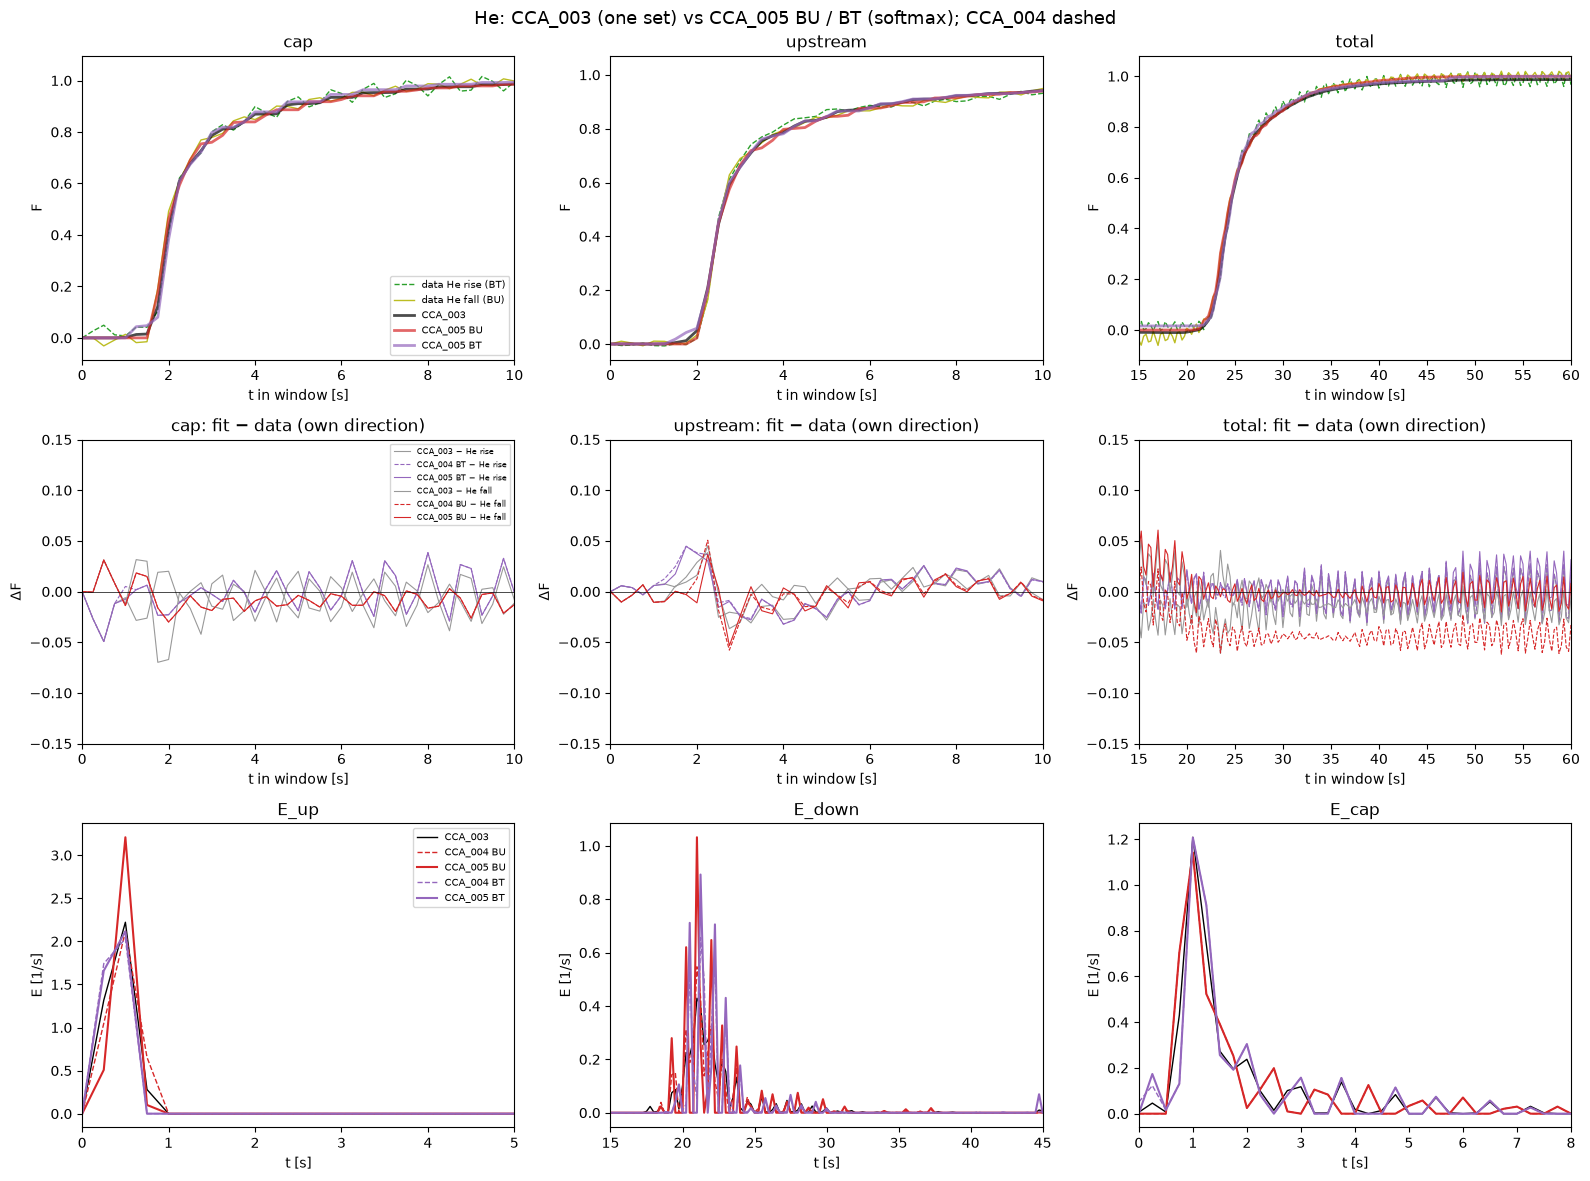

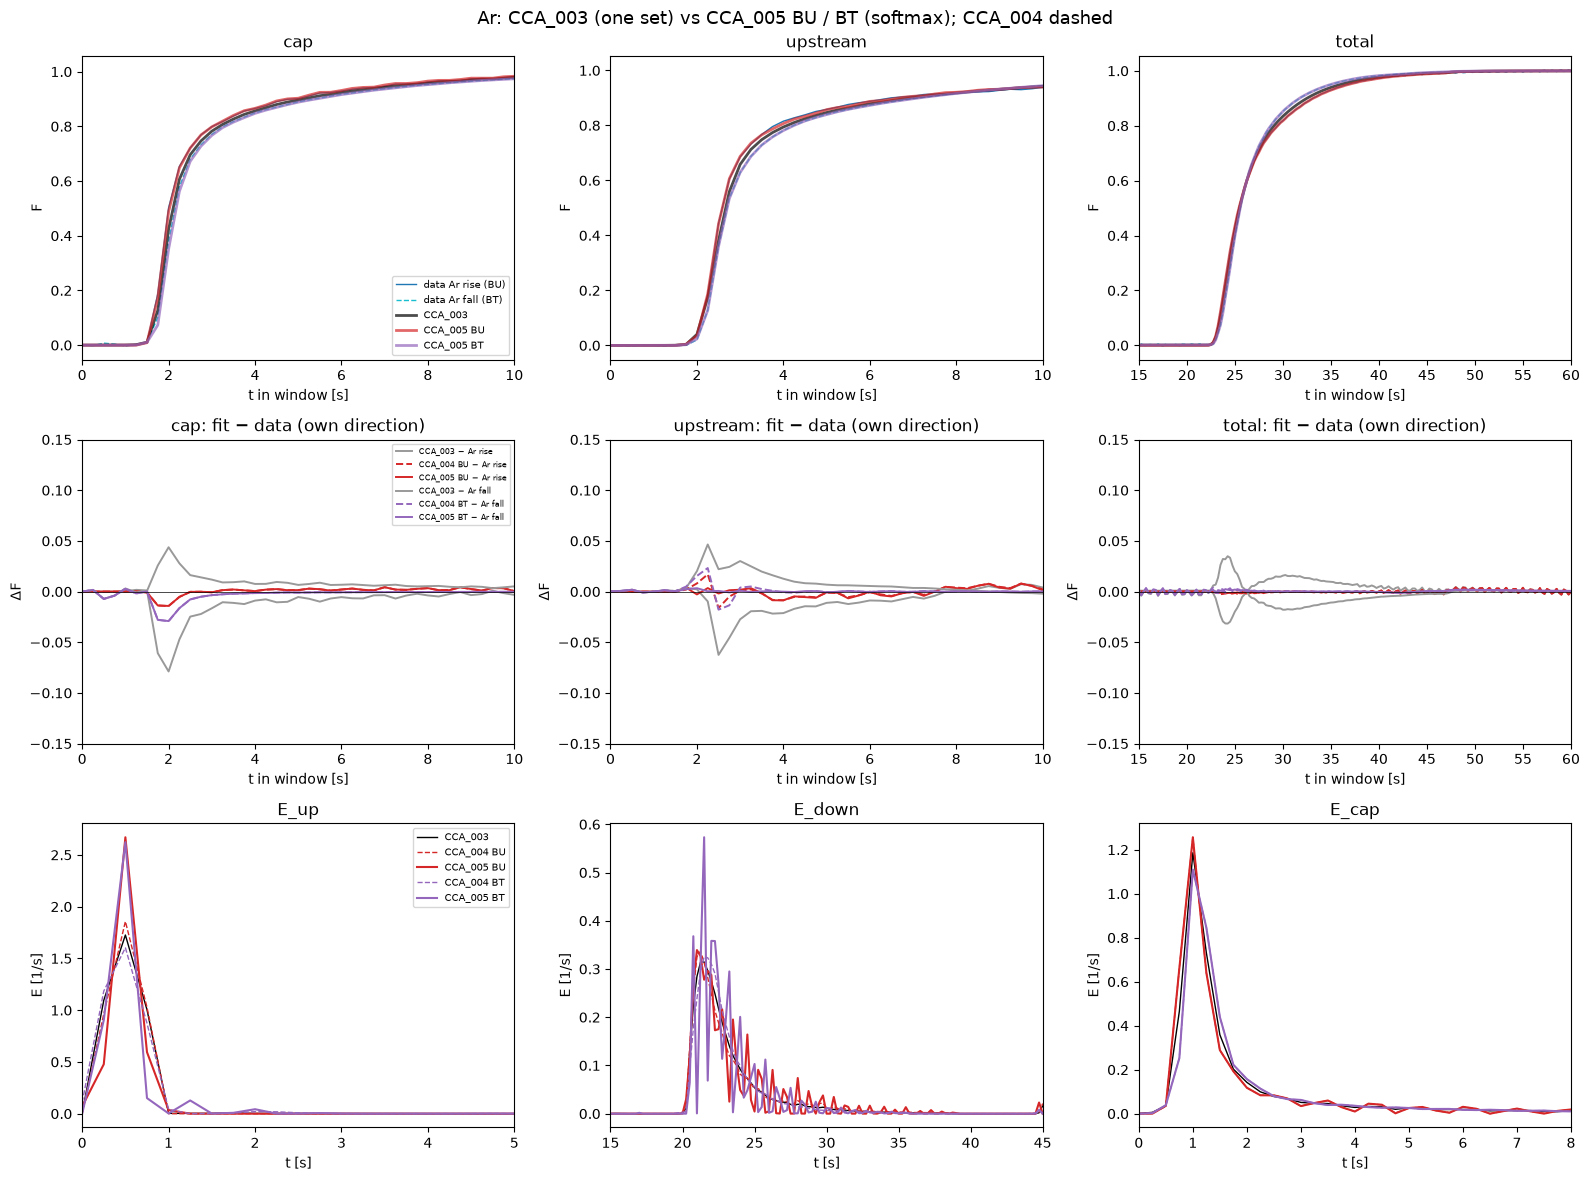

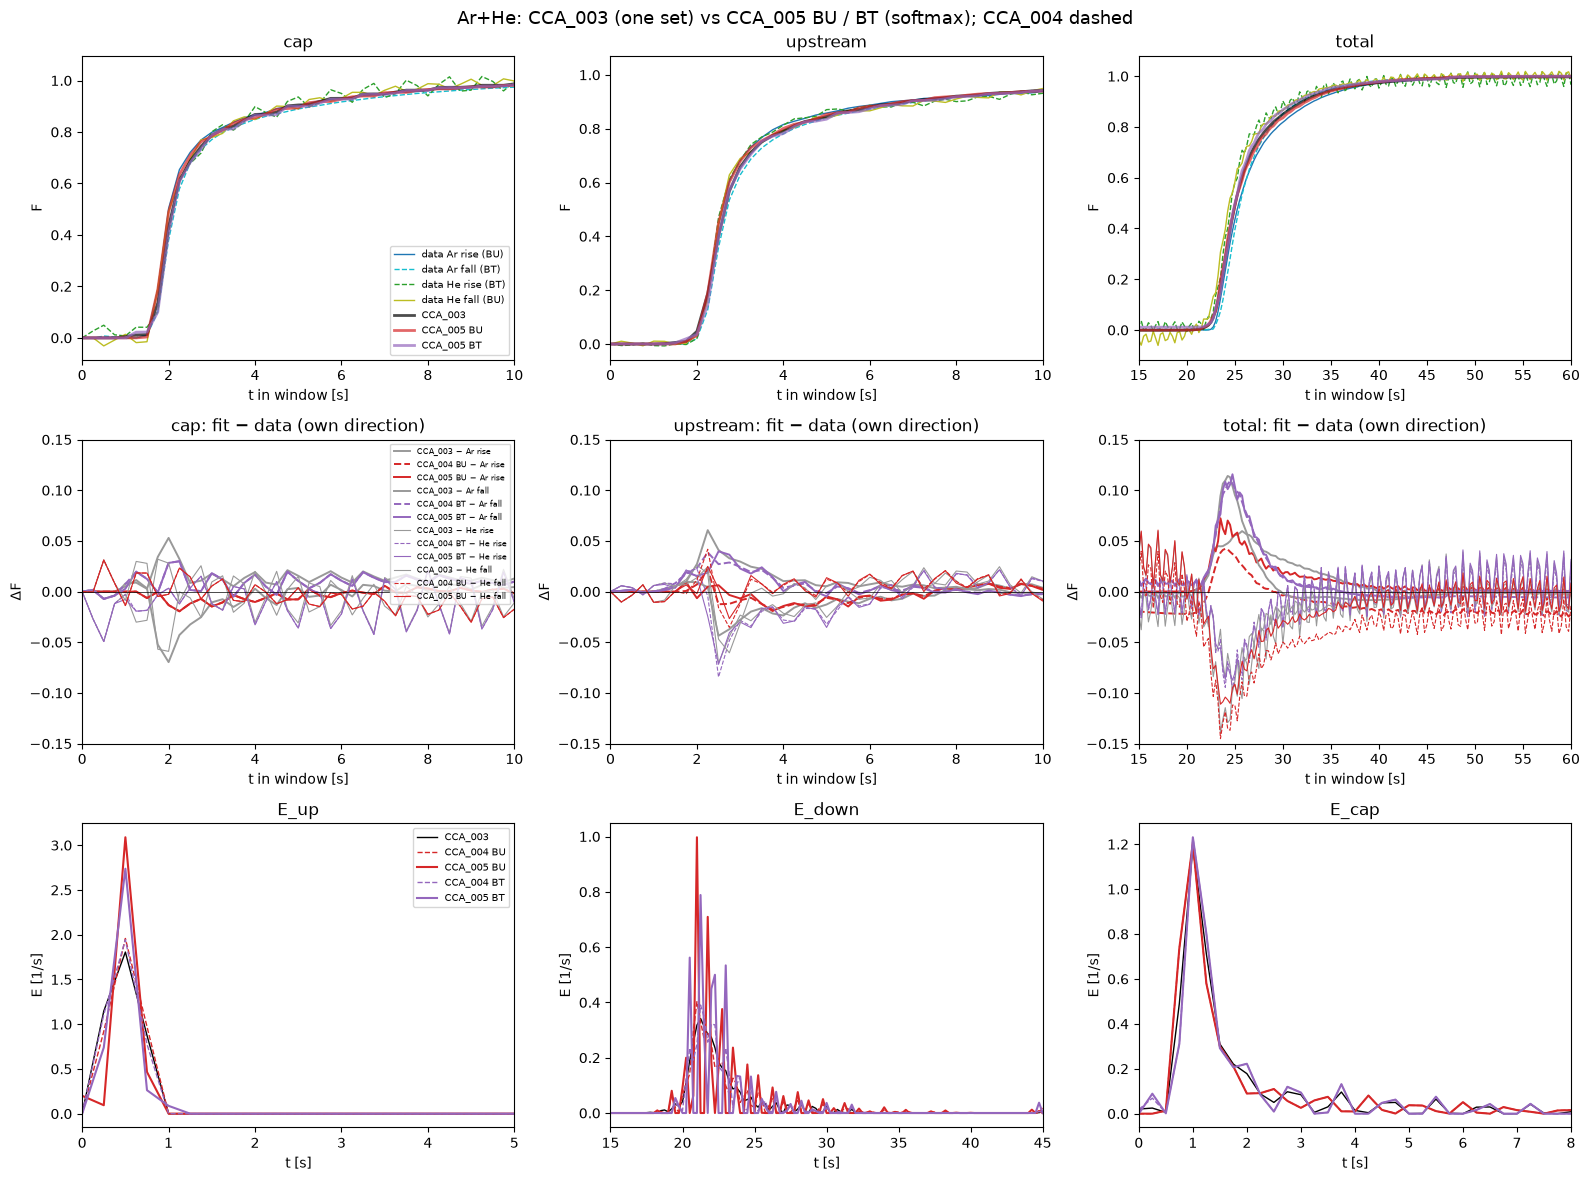

In [6]:
XLIM = {"cap": (0, 10), "upstream": (0, 10), "total": (15, 60)}
KLIM = ((0, 5), (15, 45), (0, 8))
GCOL = {"Ar rise": "C0", "Ar fall": "C9", "He rise": "C2", "He fall": "C8"}
DCOL = {"BU": "C3", "BT": "C4"}
figs = {}
for t in TRACER_SETS:
    if t not in complete:
        print(f"{LABEL[t]}: runs missing, no figure")
        continue
    own = [g for g in GROUPS if g[:2] in TRACER_SETS[t]]
    fig, ax = plt.subplots(3, 3, figsize=(16, 12))
    fig.suptitle(f"{LABEL[t]}: CCA_003 (one set) vs CCA_005 BU / BT (softmax); CCA_004 dashed", fontsize=13)
    for j, s in enumerate(SECTIONS):
        tt = ref[f"t_out {s}"][0]
        for g in own:
            ax[0, j].plot(tt, data[s, g], c=GCOL[g], lw=1, ls="-" if DIRECTION[g] == "BU" else "--", label=f"data {g} ({DIRECTION[g]})")
        ax[0, j].plot(tt, resp[t, "CCA_003", s], c="k", lw=2, alpha=0.7, label="CCA_003")
        for d in ("BU", "BT"):
            ax[0, j].plot(tt, resp[t, f"CCA_005 {d}", s], c=DCOL[d], lw=2, alpha=0.7, label=f"CCA_005 {d}")
        for g in own:
            d, lw = DIRECTION[g], 1.4 if g.startswith("Ar") else 0.8
            ax[1, j].plot(tt, resp[t, "CCA_003", s] - data[s, g], c="0.6", lw=lw, label=f"CCA_003 − {g}")
            ax[1, j].plot(tt, resp[t, f"CCA_004 {d}", s] - data[s, g], c=DCOL[d], lw=lw, ls="--", label=f"CCA_004 {d} − {g}")
            ax[1, j].plot(tt, resp[t, f"CCA_005 {d}", s] - data[s, g], c=DCOL[d], lw=lw, label=f"CCA_005 {d} − {g}")
        ax[0, j].set(xlim=XLIM[s], title=s, xlabel="t in window [s]", ylabel="F")
        ax[1, j].axhline(0, c="k", lw=0.5)
        ax[1, j].set(xlim=XLIM[s], ylim=(-0.15, 0.15), title=f"{s}: fit − data (own direction)", xlabel="t in window [s]", ylabel="ΔF")
    for i, (n, xl) in enumerate(zip(KNAMES, KLIM)):
        tk = np.linspace(*KERNEL_TIMES[i], kernels[t, "CCA_003"][i].size)
        ax[2, i].plot(tk, kernels[t, "CCA_003"][i], c="k", lw=1, label="CCA_003")
        for d in ("BU", "BT"):
            ax[2, i].plot(tk, kernels[t, f"CCA_004 {d}"][i], c=DCOL[d], lw=1, ls="--", label=f"CCA_004 {d}")
            ax[2, i].plot(tk, kernels[t, f"CCA_005 {d}"][i], c=DCOL[d], lw=1.5, label=f"CCA_005 {d}")
        ax[2, i].set(title=n, xlim=xl, xlabel="t [s]", ylabel="E [1/s]")
    ax[0, 0].legend(fontsize=7)
    ax[1, 0].legend(fontsize=6)
    ax[2, 0].legend(fontsize=7)
    fig.tight_layout()
    figs[t] = fig

## 5. Kernels: BU vs BT, CCA_004⁺ vs CCA_005

Mean residence time per kernel, the BU − BT difference, and the bed inlet (step ⊗ E_up, PTK_model_reconciliation
LOG F60): time after the step at which it reaches 0.1 / 0.5 / 0.9.

In [7]:
def bed_inlet(eu):
    t_s = np.arange(0, 35 + DT / 2, DT)
    step = (t_s >= T_STEP).astype(float)
    bed = np.convolve(np.concatenate((np.zeros(eu.size - 1), step)), eu)[eu.size - 1 : eu.size - 1 + step.size] * DT
    return t_s, bed

rows = []
for (t, k), E in kernels.items():
    if k.startswith("CCA_004 "):
        continue
    row = {"tracers": LABEL[t], "kernels": k}
    for i, n in enumerate(KNAMES):
        tk = np.linspace(*KERNEL_TIMES[i], E[i].size)
        row[f"mean t {n}"] = (tk * E[i]).sum() / E[i].sum()
        row[f"t max {n}"] = tk[np.argmax(E[i])]
    t_s, bed = bed_inlet(E[UP])
    row |= {f"bed {k_}": v for k_, v in crossings(t_s, bed).items()}
    rows.append(row)
kt = pd.DataFrame(rows).set_index(["tracers", "kernels"])
display(kt.style.format(precision=3))

rows = []
for t in complete:
    for scr in ("CCA_004⁺", "CCA_005"):
        rows.append({"tracers": LABEL[t], "kernels": scr,
                     **{n: kt.loc[(LABEL[t], f"{scr} BU"), f"mean t {n}"] - kt.loc[(LABEL[t], f"{scr} BT"), f"mean t {n}"] for n in KNAMES}})
pd.DataFrame(rows).set_index(["tracers", "kernels"]).style.format("{:+.3f}").set_caption("mean residence time BU − BT [s]")

## 6. Measured BU vs BT (for reference)

The difference between the directions in the data, against the repeat scatter (as in CCA_004_overview, section 2).

In [8]:
rows = []
for s in SECTIONS:
    t = ref[f"t_out {s}"][0]
    for tr in ("Ar", "He"):
        bu, bt = [g for g in GROUPS if g[:2] == tr and DIRECTION[g] == "BU"][0], [g for g in GROUPS if g[:2] == tr and DIRECTION[g] == "BT"][0]
        c_bu, c_bt = crossings(t, data[s, bu]), crossings(t, data[s, bt])
        rows.append({"section": s, "tracer": tr, "max |F_BU − F_BT|": np.abs(data[s, bu] - data[s, bt]).max(),
                     **{f"Δ{k} BU − BT [s]": c_bu[k] - c_bt[k] for k in c_bu},
                     "repeat std (max of both)": max(scatter[s, bu].max(), scatter[s, bt].max()),
                     "F before front, BU / BT": f"{data[s, bu][t < (20 if s == 'total' else 1.5)].mean():+.3f} / {data[s, bt][t < (20 if s == 'total' else 1.5)].mean():+.3f}"})
pd.DataFrame(rows).style.format(precision=3)

,section,tracer,max |F_BU − F_BT|,Δt10 BU − BT [s],Δt50 BU − BT [s],Δt90 BU − BT [s],repeat std (max of both),"F before front, BU / BT"
0,cap,Ar,0.123,0.000,-0.250,-0.500,0.137,+0.000 / +0.002
1,cap,He,0.089,0.000,0.000,-0.250,0.140,-0.007 / +0.023
2,upstream,Ar,0.085,0.000,0.000,-0.750,0.012,+0.000 / -0.000
3,upstream,He,0.033,0.000,0.000,-0.250,0.044,+0.005 / -0.003
4,total,Ar,0.066,-0.250,-0.250,1.500,0.013,-0.000 / +0.002
5,total,He,0.102,-0.250,-0.250,1.250,0.055,-0.030 / +0.017


## 7. Which kernel properties do the data determine?

(a) Smoothing: CCA_005's E_down smoothed with a 3-point binomial filter (n passes, renormalized), the rest unchanged;
total-system fit on the direction's own groups and the roughness RMS(Δ²E) of E_down. (b) The upstream data see
E_up ⊗ E_cap: the sum of the two mean residence times against the split, CCA_004⁺ vs CCA_005.

In [9]:
def smooth(e, n):
    for _ in range(n):
        e = np.convolve(np.pad(e, 1, mode="edge"), [0.25, 0.5, 0.25], "valid")
    return e / (e.sum() * DT)

rough = lambda e: np.sqrt(np.mean(np.diff(e, 2) ** 2))
rows = []
for t in complete:
    for d in ("BU", "BT"):
        groups = [g for g in GROUPS if DIRECTION[g] == d and g[:2] in TRACER_SETS[t]]
        cand = {"CCA_004⁺": kernels[t, f"CCA_004⁺ {d}"]}
        E5 = kernels[t, f"CCA_005 {d}"]
        cand |= {f"CCA_005, {n}× smoothed" if n else "CCA_005": [E5[0], smooth(E5[1], n) if n else E5[1], E5[2]] for n in (0, 1, 2, 4)}
        for k, E in cand.items():
            S = step_response(E, "total")
            dd = np.array([S - data["total", g] for g in groups])
            rows.append({"tracers": LABEL[t], "direction": d, "E_down": k, "rms ΔF total": np.sqrt(np.mean(dd**2)),
                         "max |ΔF| total": np.abs(dd).max(), "roughness E_down": rough(E[1]), "peak E_down [1/s]": E[1].max()})
display(pd.DataFrame(rows).set_index(["tracers", "direction", "E_down"]).style.format(precision=4))

rows = []
for t in complete:
    for d in ("BU", "BT"):
        for scr in ("CCA_004⁺", "CCA_005"):
            m = kt.loc[(LABEL[t], f"{scr} {d}")]
            rows.append({"tracers": LABEL[t], "direction": d, "kernels": scr, "mean t E_up": m["mean t E_up"], "mean t E_cap": m["mean t E_cap"],
                         "E_up + E_cap": m["mean t E_up"] + m["mean t E_cap"], "mean t E_down": m["mean t E_down"]})
pd.DataFrame(rows).set_index(["tracers", "direction", "kernels"]).style.format(precision=3).set_caption("mean residence times [s]")

## 8. Findings (facts from the tables above, state 2026-11-02; the choice is Hannes')

Runs: CCA_003, CCA_004 and CCA_005 for Ar, He, Ar+He (all seed 0, 20000 epochs per stage); identical data in all
runs (section 1).

**The softmax does what it should.** All CCA_005 kernels have ΣE·dt = 1.0000 and no negative values (section 2).
CCA_004 as stored had negative mass of −0.043 (He BU E_down) and −0.023 (Ar+He BU E_down); CCA_003 He −0.011. The
He BU plateau deficit of CCA_004 is gone: total-system RMS ΔF on He fall 0.0177 (CCA_004 0.0427, CCA_004 clamped
afterwards 0.0176).

**Fit quality CCA_005 vs CCA_004⁺ (CCA_004 clamped afterwards), largest max |ΔF| (section 3):**
- Ar: capillary 2.9 / 2.9 %, upstream 0.9 / 2.3 % (Ar fall 0.3 %, RMS 0.0008), total 0.5 / 0.4 %. CCA_003: 7.9 / 6.2 /
  3.5 %.
- He: 4.9 / 4.9 %, 5.3 / 5.8 %, 6.3 / 6.3 %; He rise in the total system 4.2 vs 3.2 %. CCA_003: 7.0 / 4.5 / 6.1 %.
- Ar+He: 4.9 / 4.9 %, 7.2 / 8.4 %, 11.6 / 12.3 %. CCA_003: 7.0 / 7.0 / 13.9 %. The total system stays dominated by the
  Ar/He timing difference (residual peaks around 24 s of +11 % on Ar fall and −14 % on He, CCA_003 as well).
- Fixed integral in the capillary: RMS slightly higher than CCA_004⁺ on the rises (Ar 0.0041 vs 0.0032, He 0.0204 vs
  0.0191), equal or lower on the falls, same max |ΔF|.
- Other direction's kernels (CCA_005 other): worse than own everywhere for Ar (total 6.5 vs 0.5 %); for He upstream
  the other direction's kernels do no worse (4.1 vs 5.3 %), consistent with He's BU/BT difference there being below its
  repeat scatter (section 6).

**The kernel shape at grid scale is not determined by the data (section 7a).** CCA_005's E_down is a comb
alternating between ≈ 0 and peaks up to 0.57 s⁻¹ (Ar BT) or 1.0 s⁻¹ (He BU, Ar+He BU). CCA_004⁺'s are smoother:
roughness RMS(Δ²E) Ar 0.011 / 0.008 (BU / BT) vs 0.052 / 0.127 in CCA_005, Ar+He 0.032 / 0.045 vs 0.23 / 0.20; He is
rough in both (0.08 / 0.16 vs 0.24 / 0.23). Smoothing CCA_005's E_down once (roughness 3–5× lower) changes the
total-system RMS by ≤ 0.0002 (Ar BU 0.0015 → 0.0016, He BU 0.0177 → 0.0177, Ar+He BU 0.0203 → 0.0203), and CCA_004
reached the same loss with the smoother kernels (scratchpad scan: Ar BU total 4.683e-8 clamp vs 4.697e-8 softmax).
The comb is a property of the optimizer path in logit space (multiplicative updates drift towards sparse kernels),
not of the data. The same holds for the E_up peak (2.7–3.2 vs 1.8–2.1 s⁻¹, within 4 grid points) and E_up(0)
(CCA_005 Ar BU 0.069, Ar+He BU 0.200 s⁻¹, i.e. 5 % of the step instantly; CCA_005 BT and He 0.000).

**What is determined** (CCA_004⁺ vs CCA_005, independent optimizer paths):
- Ar E_down mean residence time: BU 23.336 / 23.332 s, BT 22.949 / 22.942 s; BU − BT +0.39 s in both. Ar+He BU 22.869 /
  22.871 s (BT 22.230 / 22.369).
- E_up + E_cap mean times (what the upstream data see): within 0.035 s (Ar BU 2.876 / 2.867 s, BT 2.984 / 2.999 s;
  largest difference He BT 2.874 / 2.841 s).
  Their split is not: E_up moves by up to 0.11 s and E_cap by 0.15 s (He BT E_up 0.894 → 1.006 s, E_cap 1.980 → 1.835
  s; Ar BU E_up 0.921 → 1.004 s). The split comes from the capillary stage (5 rows per direction, 4 for training).
- Bed inlet (step ⊗ E_up): t50 = 0.5 s after the step in all kernel sets; t90 0.5–0.75 s; at the 0.25 s grid the
  E_up differences only show in t10 (Ar+He CCA_005 BU 0.5 s, all others 0.25 s).

**Not determined:** He's direction difference in E_down (BU − BT +0.39 s in CCA_004⁺, +0.02 s in CCA_005; He BT E_down
21.74 vs 22.05 s); the E_up/E_cap split at the 0.1 s level; peak heights and E(0).

**What each choice buys** (no ranking):
- CCA_005 (softmax): exact ΣE·dt = 1 and E ≥ 0, best Ar upstream fit (0.9 %), same total-system fits; kernels rough
  at grid scale, which matters wherever the kernel shape itself is used (e.g. plots, peak values, E(0)), not for
  responses at the 0.25 s grid.
- CCA_004⁺ (CCA_004 clamped afterwards): smoother kernels at the same fit quality (He rough in both); integrals free (0.994–1.012), so a
  level mismatch is partly absorbed by ΣE·dt.
- Not implemented: a smoothness penalty (e.g. on Δ²E or on the logits) in the softmax fit would give unit-integral
  kernels without the comb; separate Ar / He E_down for Ar+He (the remaining total-system error).